# Пример · #22 Sigmoid (эталон) · **easy**

Открывай **после** попытки в [22_sigmoid.ipynb](./22_sigmoid.ipynb).

**Два уровня ментора на этом примере:**

1. **Уровень 1** — формула на `math`/`NumPy`, производная, график (понимание + §34.5).
2. **Уровень 2** — те же `z`, что и в PyTorch: `torch.sigmoid` (без округления для сверки).
3. **Submit** — на сайт идёт **отдельная** обёртка с `round(..., 4)` как в условии #22.

Остальные активации — тот же каркас: *реализовал → (график) → сверил с `F.*` → submit*.

In [13]:
import math
import numpy as np
import torch
import matplotlib.pyplot as plt


def need(cond, msg=""):
    assert cond, msg or "проверка не прошла"

## Уровень 1a · формула (то, что пойдёт на Deep-ML)

$\sigma(z) = \dfrac{1}{1+e^{-z}}$, на сайте — `round(..., 4)`.

In [14]:
def sigmoid_unrounded(z: float) -> float:
    return 1.0 / (1.0 + math.exp(-z))


def sigmoid(z: float) -> float:
    """Как копировать на deep-ml.com/problems/22"""
    return round(sigmoid_unrounded(z), 4)


def sigmoid_derivative(z: float) -> float:
    s = sigmoid_unrounded(z)
    return s * (1.0 - s)


need(sigmoid(0) == 0.5)
need(abs(sigmoid_derivative(0) - 0.25) < 1e-9)
print("sigmoid(0) =", sigmoid(0), " σ′(0) =", sigmoid_derivative(0))

sigmoid(0) = 0.5  σ′(0) = 0.25


## Уровень 1b · график

Видно: σ сжимается в (0,1); σ′ максимум в 0 (= 0.25) — отсюда затухание градиента в глубине (handbook §34.5).

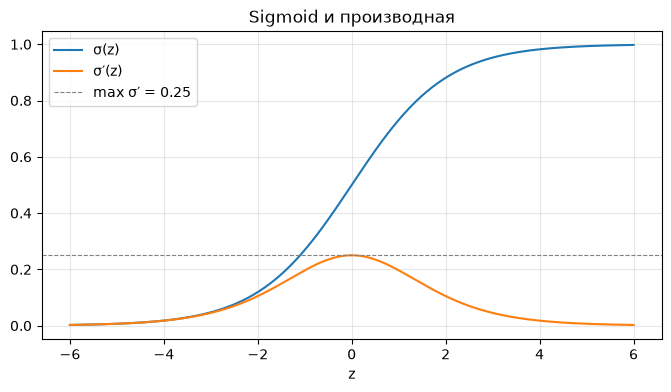

In [15]:
xs = np.linspace(-6, 6, 200)
ys = np.array([sigmoid_unrounded(x) for x in xs])
dys = np.array([sigmoid_derivative(x) for x in xs])

plt.figure(figsize=(8, 4))
plt.plot(xs, ys, label="σ(z)")
plt.plot(xs, dys, label="σ′(z)")
plt.axhline(0.25, color="gray", ls="--", lw=0.8, label="max σ′ = 0.25")
plt.xlabel("z")
plt.legend()
plt.grid(True, alpha=0.3)
plt.title("Sigmoid и производная")
plt.show()

## Уровень 2 · PyTorch

Сверяем **без** `round`: библиотека считает полную точность.

In [16]:
z = torch.tensor([-2.0, 0.0, 3.0])
mine = np.array([sigmoid_unrounded(t) for t in z.tolist()])
ref = torch.sigmoid(z).numpy()

need(np.allclose(mine, ref, rtol=1e-6))
for zi, mi, ri in zip(z.tolist(), mine, ref):
    print(f"z={zi:+.1f}  mine={mi:.6f}  torch={ri:.6f}  round(mine)={round(mi,4)}")

z=-2.0  mine=0.119203  torch=0.119203  round(mine)=0.1192
z=+0.0  mine=0.500000  torch=0.500000  round(mine)=0.5
z=+3.0  mine=0.952574  torch=0.952574  round(mine)=0.9526


## Submit на Deep-ML

В редактор на [problems/22](https://www.deep-ml.com/problems/22) — **только** это (у тебя должно быть своё, набранное в тренажёре):

```python
import math

def sigmoid(z: float) -> float:
    return round(1 / (1 + math.exp(-z)), 4)
```

После Accepted — галочка в [README.md](./README.md) и по желанию тот же `sigmoid` в `13_deep_ml_deep_learning.py`.